# 03 · 少看历史会丢掉什么：四种读取方式在真实问题上的质量对照

**这是一份只读实验课：** 它加载 `reports/` 下已保存的 G2-lite 结果（基线可用性、四方法对照、覆盖率、代表案例的真实选择位置、反事实改写、成本），展示与那些结果同一版本的正式源码，并用一个随机初始化的 2 层小 Qwen3（真实模块代码，CPU float64）重放 B / C / D0 三种选择器的契约。它不加载 0.6B 模型、不跑 GPU、不训练。重跑的入口是 `bench/g2lite_quality.py`（三遍：A 基线 → 可用格子上的四方法对照 → 反事实改写）与 `scripts/g2lite_report.py`，不由本页隐式触发。

G1b 回答了速度一侧：同模型同设备下，未训练索引读取的整步收益不足 10%，速度主线收口。本页回答质量一侧的一个缩减问题：**当模型只能读一小部分历史时，它丢掉了什么？** 四种读取方式在同一前缀、同一问题、同一名额下作答：

| 方法 | 读什么 | 名额给谁 |
|---|---|---|
| A 完整读取 | 全部合法位置 | — |
| B 近期窗口 | F ∪ 最近的 k 个候选位置 | 最近的位置 |
| C 均匀随机 | F ∪ 候选域内均匀抽取的 k 个位置（固定种子，每层每组独立） | 随机 |
| D0 未训练索引 | F ∪ 随机初始化 GroupedIndexer 打分的 top-k | 由内容决定但权重未训练 |

F = 首 4 ∪ 近 64；B、C、D0 的实际读取数都是 68 + k0。**C 不叫"随机筛选"，D0 也不叫**：C 的选择与内容无关，D0 的选择由内容决定但没有学过。每个案例按固定结构：资料与问题 → 运行前预测 → 四种方法实际回答 → 各自选择的位置 → 改动一处资料再检查 → 哪些解释得到支持、哪些仍不确定。所有数字来自 Mac M4 Max 的 MPS 实测；**48 份是探索样本，不做区间统计，不支持"损失小于 2 个百分点"或其反面；D0 未训练，B 由窗口几何决定。**


## 0. 定位仓库、加载已保存结果、核对源码版本

结果与代码必须锁在同一版本：下面把当前源码的哈希与三遍 run 的 manifest 记录的哈希逐个对照，并核对模型 / tokenizer revision、配置版本与数据 digest。

In [1]:
from pathlib import Path
import hashlib, inspect, json, sys, textwrap
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".attention_lab_bootstrap").is_file()), None)
assert root is not None, "请从 attention-lab 项目目录或 notebooks 子目录打开本页"
sys.path.insert(0, str(root / "src"))

def load(rel):
    p = root / rel
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None

summary = load("reports/g2lite_summary_mac_m4max.json")      # 表格、案例、改写、成本（精简）
answers = load("reports/g2lite_answers_mac_m4max.json")      # 逐题回答与解析结果
manifests = load("reports/g2lite_manifest_mac_m4max.json")   # 三遍 run 的 manifest
cfg = load("configs/mac_g2lite.json")
if summary is None or answers is None or manifests is None:
    print("未执行：reports/ 下没有 G2-lite 结果。入口：python bench/g2lite_quality.py --methods A --tag pass1-A 等三遍，再 python scripts/g2lite_report.py")
else:
    print("基线 run:", summary["baseline_run"], "| 对照 run:", summary["comparison_run"], "| 改写 run:", summary["rewrite_runs"])
    print("配置版本:", summary["config_version"], "| ρ:", summary["rho"], "| 可用格子:", summary["usable_cells"])
    for m in manifests["runs"]:
        print(f"{m['run_id']:<40s} commit {m['git']['commit'][:10]} dirty {m['git']['dirty_diff_sha256']} model {m['model_revision'][:10]} tokenizer {m['tokenizer_revision'][:10]} data {m['data_sha256'][:12]} config v{m['config_version']} HF_HUB_OFFLINE={m['hf_hub_offline']}")


基线 run: g2lite-20261017T130007Z-pass1-A | 对照 run: g2lite-20261017T130319Z-pass2-ABCD0 | 改写 run: ['g2lite-20261017T130551Z-pass3a-rewrites', 'g2lite-20261017T130715Z-pass3b-move']
配置版本: 2 | ρ: [0.03125, 0.125] | 可用格子: ['T1/2K', 'T1/8K']
g2lite-20261017T130007Z-pass1-A          commit af62df48d2 dirty None model c1899de289 tokenizer c1899de289 data 0cc835f0a637 config v2 HF_HUB_OFFLINE=1
g2lite-20261017T130319Z-pass2-ABCD0      commit af62df48d2 dirty None model c1899de289 tokenizer c1899de289 data 00dd5a7d0e4f config v2 HF_HUB_OFFLINE=1
g2lite-20261017T130551Z-pass3a-rewrites  commit af62df48d2 dirty None model c1899de289 tokenizer c1899de289 data 92bfe3568382 config v2 HF_HUB_OFFLINE=1
g2lite-20261017T130715Z-pass3b-move      commit af62df48d2 dirty None model c1899de289 tokenizer c1899de289 data d88880dddadb config v2 HF_HUB_OFFLINE=1


In [2]:
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
if manifests:
    files = ["src/attention_lab/decode.py", "src/attention_lab/qwen_wrap.py", "src/attention_lab/g2lite_data.py", "src/attention_lab/g2lite_eval.py", "bench/g2lite_quality.py"]
    for rel in files:
        now = sha(root / rel)
        rec = {m["run_id"]: m["source_hashes"].get(rel) for m in manifests["runs"]}
        print(f"{rel:<40s} 当前 {now[:12]}  " + "  ".join(f"{k.split('-')[1][:15]}:{'一致' if v == now else '不同'}" for k, v in rec.items()))


src/attention_lab/decode.py              当前 273e3abe8093  20261017T130007:一致  20261017T130319:一致  20261017T130551:一致  20261017T130715:一致
src/attention_lab/qwen_wrap.py           当前 a4ae836a3ae6  20261017T130007:一致  20261017T130319:一致  20261017T130551:一致  20261017T130715:一致
src/attention_lab/g2lite_data.py         当前 7a82de22754a  20261017T130007:一致  20261017T130319:一致  20261017T130551:一致  20261017T130715:一致
src/attention_lab/g2lite_eval.py         当前 be8cc6a17cd0  20261017T130007:一致  20261017T130319:一致  20261017T130551:一致  20261017T130715:一致
bench/g2lite_quality.py                  当前 d397c5013ada  20261017T130007:一致  20261017T130319:一致  20261017T130551:一致  20261017T130715:一致


**读法。** 三遍正式 run 都在同一个提交（`af62df4`）、干净工作树上运行，manifest 记录的五个源码文件哈希与当前文件全部一致，模型与 tokenizer revision 同为 `c1899de…`，配置是 v2（校准后冻结，见卡片附录），数据 digest 相同。本页展示的源码就是跑出结果的源码。

## 1. 四种读取方式的正式代码与契约

**运行前的预测**（`reports/cards/G2lite_mac_m4max.md`）：B、C、D0 在同一 ρ 下读取数相同、都包含 F；全选时三者退化为 A；B 的额外行恰为最近的 k 个候选；C 的抽取由种子决定且回退重放不变；B、C 不打分。下面并排打印三个名单生成函数与共用的取行核，再在小模型上逐条验证。

In [3]:
import warnings; warnings.filterwarnings("ignore")
import torch
from attention_lab import decode, qwen_wrap
for fn in (decode.select_rows_kernel, decode.select_rows_recent, decode.select_rows_uniform, decode.gathered_decode_step_kernel):
    print(inspect.getsource(fn))


W1017 21:17:23.296000 64989 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


def select_rows_kernel(u, zT, fixed_rows, off_lo, lo: int, hi: int, k: int) -> torch.Tensor:
    """D0: score the candidate columns once, top-k once, merge with the fixed rows. Returns flat row ids [B*G*S]."""
    B, G = fixed_rows.shape[:2]
    if k <= 0:
        return fixed_rows.reshape(-1)
    scores = candidate_scores(u, zT, lo, hi)                       # [B,G,1,M]
    top = torch.topk(scores, k, dim=-1).indices.view(B, G, k)      # the only top-k, over the candidate domain
    return torch.cat([fixed_rows, top + off_lo], dim=-1).view(-1)  # original positions as row ids

def select_rows_recent(fixed_rows, off_lo, lo: int, hi: int, k: int) -> torch.Tensor:
    """B: the k most recent candidate positions [hi-k, hi) merged with the fixed rows. Same F and count as D0.

    Candidate-relative index i in [0, hi-lo) maps to row off_lo + i, exactly as the top-k indices do in
    `select_rows_kernel`; nothing is scored, nothing is renumbered.
    """
    B, G = fixed_rows.shape[:2]
    i

In [4]:
# 封装里的分派：同一个解码分支，只有名单来源不同
src = inspect.getsource(qwen_wrap.LabAttention.forward)
i = src.index('if st.mode == "sparse":'); j = src.index("else:   # prefill")
print(textwrap.dedent(src[i:j]))


if st.mode == "sparse":
                plan = st.plan
                if plan is None or plan.legal_length != L0 + 1:
                    raise RuntimeError("sparse decode needs a StepPlan built for this step's legal length")
                if st.selector == "index":                    # D0: score, top-k, merge with F (G1b path, unchanged)
                    idx = st.indexers[l]
                    cache.append(l, k_main, v)                # K/V once; z of the new key is written by the kernel below
                    out, rows = sparse_decode_step_kernel(q5, q_pre.view(B, G, h, 1, d), cache.k[l], cache.v[l], cache.z[l],
                                                          idx.wq_t_scaled, idx.wk, plan.fixed_rows, plan.off_lo, plan.lo,
                                                          plan.hi, plan.k, plan.selected_count, k_pre_new=k_pre,
                                                          write_col=plan.write_col, scale=self.scaling, return_rows=True)
           

In [5]:
# 小模型契约重放（CPU float64，2 层随机 Qwen3）：同 F 同名额同读取数；B = 最近 k 个候选；C 由种子决定；全选退化为 A；污染未选行不改变 B / C
from attention_lab.qwen_wrap import tiny_qwen3, wrap_model, unwrap_model, make_state, LabRunner
from attention_lab.selection import FIXED_PREFIX, FIXED_RECENT, fixed_budget
torch.manual_seed(0)
m = tiny_qwen3(); ids = torch.randint(0, 256, (1, 130), generator=torch.Generator().manual_seed(31))
holder = wrap_model(m); PRE = 100
def run_sel(selector, k0=None, seed=3):
    st = make_state(m, 160, "sparse", selector=selector, uniform_seed=seed); run = LabRunner(m, holder, st)
    run.prefill(ids[:, :PRE], 37); st.begin_request(None if k0 else 1/8, k0=k0); st.record_selection = True
    out = run.step(ids[:, PRE:PRE+1]); return st, run, out
with torch.inference_mode():
    S = {name: run_sel(sel) for name, sel in (("B", "recent"), ("C", "uniform"), ("D0", "index"))}
    legal = PRE + 1; F = set(range(FIXED_PREFIX)) | set(range(legal - FIXED_RECENT, legal)); lo, hi = FIXED_PREFIX, legal - FIXED_RECENT
    print(f"合法长度 {legal}，k0 = {fixed_budget(legal, 1/8)}，候选域 [{lo}, {hi})，F 有 {len(F)} 个位置")
    for name, (st, run, out) in S.items():
        pos = (st.last_rows[0].view(st.cache.groups, -1) - st.cache.offsets.view(-1, 1))[0].tolist()
        extra = sorted(set(pos) - F)
        print(f"{name:<3s} 读取数 {len(pos)} = {st.plan.selected_count}  含 F: {F.issubset(pos)}  额外 {len(extra)} 个候选: {extra}")
    # 全选退化
    stA = make_state(m, 160, "full"); runA = LabRunner(m, holder, stA); runA.prefill(ids[:, :PRE], 37); outA = runA.step(ids[:, PRE:PRE+1])
    for name, sel in (("B", "recent"), ("C", "uniform"), ("D0", "index")):
        st, run, out = run_sel(sel, k0=160)
        print(f"全选 {name}: 读取数 {st.plan.selected_count} = 合法长度 {st.plan.legal_length}, 对 A 的 max|Δ| = {float((out - outA).abs().max()):.2e}")
    # 污染未选行：B / C 逐位不变，A 坏掉
    for name, sel in (("B", "recent"), ("C", "uniform")):
        st, run, clean = run_sel(sel)
        stA2 = make_state(m, 160, "full"); runA2 = LabRunner(m, holder, stA2); runA2.prefill(ids[:, :PRE], 37); runA2.step(ids[:, PRE:PRE+1])
        for l in range(st.cache.layers):
            pos = (st.last_rows[l].view(st.cache.groups, -1) - st.cache.offsets.view(-1, 1))
            for g in range(st.cache.groups):
                keep = torch.zeros(160, dtype=torch.bool); keep[pos[g]] = True
                st.cache.k[l][0, g, ~keep] = float("nan"); st.cache.v[l][0, g, ~keep] = float("nan")
                stA2.cache.k[l][0, g, ~keep] = float("nan"); stA2.cache.v[l][0, g, ~keep] = float("nan")
        run.rollback(PRE); runA2.rollback(PRE)
        again = run.step(ids[:, PRE:PRE+1])
        print(f"污染未选行后 {name}: 逐位相同 = {torch.equal(again, clean)}；完整读取 A 出现 NaN = {not torch.isfinite(runA2.step(ids[:, PRE:PRE+1])).all().item()}")
    unwrap_model(m)


合法长度 101，k0 = 13，候选域 [4, 37)，F 有 68 个位置
B   读取数 81 = 81  含 F: True  额外 13 个候选: [24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
C   读取数 81 = 81  含 F: True  额外 13 个候选: [8, 9, 12, 13, 14, 17, 20, 21, 26, 27, 30, 34, 36]
D0  读取数 81 = 81  含 F: True  额外 13 个候选: [4, 6, 7, 12, 13, 15, 16, 19, 24, 25, 26, 28, 32]
全选 B: 读取数 101 = 合法长度 101, 对 A 的 max|Δ| = 0.00e+00
全选 C: 读取数 101 = 合法长度 101, 对 A 的 max|Δ| = 0.00e+00
全选 D0: 读取数 101 = 合法长度 101, 对 A 的 max|Δ| = 0.00e+00
污染未选行后 B: 逐位相同 = True；完整读取 A 出现 NaN = True
污染未选行后 C: 逐位相同 = True；完整读取 A 出现 NaN = True


**解释。** 三种方法的差别只在「名额给谁」：读取数、固定集合 F、取行核都相同，所以后面的质量差别不能归因于读得多或少，只能归因于读了哪些位置。污染测试说明 B 和 C 的输出只由它们名单上的行决定——这也是后面「覆盖率」这个量有意义的前提：名单之外的行对输出没有影响。

## 2. 资料、问题与协议

**协议 `document_dense_then_sparse`。** 资料前缀（聊天模板头 + 表头 + 记录与填充）用完整读取处理一次并建索引表，问题不在前缀里；每个请求克隆这份前缀缓存，从问题第一个 token 起逐 token 用自己的读取方式（问题、模板尾部、生成的每个 token 都是一步解码）；贪心，≤ 64 新 token，EOS 停止；资料改写后重建前缀。下面展示生成器的布局函数与一份实际资料。

In [6]:
from attention_lab import g2lite_data, g2lite_eval
print(inspect.getsource(g2lite_data.layout_document)[:2600])
print(inspect.getsource(g2lite_eval.score_answer))


def layout_document(tok, cfg: dict, rng: random.Random, ids: list[str], values: list[str], question: str) -> tuple[list, dict]:
    """Place n records in filler so that the prefix has about `target_tokens` tokens and the last two records end at the
    configured distances from the end (back_far, then back_near); the other records are spread evenly over the body."""
    data, lay = cfg["data"], cfg["data"]["layout"]
    n = len(ids)
    fmt, pool, joiner = data["record_format"], data["filler_pool"], data.get("filler_joiner", "")
    lines = [fmt.format(id=i, value=v) for i, v in zip(ids, values)]
    cache = {}
    d_near = rng.randint(*lay["back_near_tokens_from_end"])
    d_far = rng.randint(*lay["back_far_tokens_from_end"])
    streams = [FillerStream(rng, pool, tok, cache, joiner) for _ in range(n + 1)]  # one fixed stream per gap (before each record, and after the last)
    per = len(encode(tok, lines[0] + lines[1])) - len(encode(tok, lines[0]))
    target = int(data["lengths"][cf

In [7]:
if summary:
    d = summary["docs"]["T1-2K-00"]
    print("doc_id T1-2K-00 ·", d["task"], d["length_tag"], "· 目标桶", d["buckets"], "· 记录数", d["n_records"], "· 前缀 token", d["prefix_token_count"], "· 问题+模板尾 token", d["suffix_token_count"])
    print("问题:", d["question"], "| 目标值:", d["targets"], "| 目标距前缀末尾 token:", d["target_distance_from_prefix_end"], "| 倒数第几条:", d["target_records_from_end"])
    print()
    print("几何（全部正式资料）：")
    rows = sorted((v for v in summary["docs"].values() if v["variant"] == "base"), key=lambda v: (v["task"], v["length_tag"]))
    print(f"{'doc':<10} {'桶':<18} {'前缀':>6} {'尾部':>4} {'目标距末尾 token':>18} {'倒数第几条':>10}")
    for v in rows:
        print(f"{v['task']+'-'+v['length_tag']+'-'+v['question'][3:7]:<10} {'/'.join(v['buckets']):<18} {v['prefix_token_count']:>6} {v['suffix_token_count']:>4} {str(v['target_distance_from_prefix_end']):>18} {str(v['target_records_from_end']):>10}")


doc_id T1-2K-00 · T1 2K · 目标桶 ['front'] · 记录数 16 · 前缀 token 2050 · 问题+模板尾 token 35
问题: 问题：编号 1563 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。 | 目标值: ['8422'] | 目标距前缀末尾 token: [1888] | 倒数第几条: [15]

几何（全部正式资料）：
doc        桶                      前缀   尾部        目标距末尾 token      倒数第几条
T1-2K-编号 1 front                2050   35             [1888]       [15]
T1-2K-编号 1 front                2060   35             [1787]       [14]
T1-2K-编号 6 front                2056   35             [1892]       [15]
T1-2K-编号 5 front                2037   35             [1875]       [15]
T1-2K-编号 5 middle               2057   35             [1271]       [10]
T1-2K-编号 4 middle               2046   35             [1167]        [9]
T1-2K-编号 3 middle               2044   35             [1152]        [9]
T1-2K-编号 8 middle               2041   35             [1273]       [10]
T1-2K-编号 8 back_near            2043   35               [51]        [0]
T1-2K-编号 2 back_near            2041   35               [57]        [0]
T1-2K-编号 1 b

**读法。** 每份资料 16 条记录穿插在无数字的中文填充句之间，前缀 2037–2060 或 8181–8204 token；问题与模板尾部 35（T1）或 54（T2）token。名额由请求起始长度决定：2K 时 k0 = 64（ρ = 1/32）/ 256（1/8），8K 时 256 / 1024，B、C、D0 的读取数都是 68 + k0。B 的窗口在生成第一个答案 token 那一步覆盖的资料 token 数是 64 + k0 − Q：T1 在 2K 为 93 / 285，在 8K 为 285 / 1053。尾部两条记录放在受控距离上：倒数第一条（back_near，行末距末尾 32–60 token）在四个设置下都落在 B 的窗口内，倒数第二条（back_far，150–250 token）只在 2K · ρ = 1/32 之外的三个设置内；front / middle 永远在窗口外；F 的近 64 不含任何记录。这是用几何预先把「B 应该在哪些资料上对」写死，再去看模型是否照做。

## 3. 基线可用性（第一遍：A 在全部格子）

**运行前的预测**（卡片原文，写于 v1 密集表设计）：T1-2K 10–12/12，T2-2K 7–11/12，T1-8K 6–11/12，T2-8K 3–9/12。**校准后的修订预测**（卡片附录，写于正式运行前）：T1 两档可用（2K 10–12，8K 9–12），T2 两档不可用（2K 3–7，8K 0–3）。门槛 80% 是小样本可用性检查。

In [8]:
if summary:
    print(f"{'格子':<8} {'n':>3} {'对':>3} {'率':>6} {'答成编号':>8} {'任意顺序含全部目标':>18} {'格式错误':>8} {'截断':>5}  按目标位置")
    base_rows = [r for r in answers if r["run_id"] == summary["baseline_run"]]
    for c, t in summary["baseline_methods"].items():
        a = t["A"]; rows_c = [r for r in base_rows if f"{r['task']}/{r['length_tag']}" == c]
        print(f"{c:<8} {a['n']:>3} {a['hits']:>3} {a['rate']*100:>5.0f}% {sum(r['answered_with_ids'] for r in rows_c):>8} {a['any_order']*100:>17.0f}% {a['format_errors']:>8} {a['truncated']:>5}  " + "; ".join(f"{b} {v*100:.0f}%" for b, v in a["by_bucket"].items()) + f"   可用: {summary['gate'][c]['usable']}")
    print()
    for r in base_rows:
        if not r["exact_match"]:
            print(f"  ✗ {r['doc_id']:<10} 桶 {'/'.join(r['buckets']):<18} 目标 {r['targets']} 回答 {r['predicted']} 文本 {r['text'][:40]!r}")


格子         n   对      率     答成编号          任意顺序含全部目标     格式错误    截断  按目标位置
T1/2K     12  12   100%        0               100%        0     0  back_far 100%; back_near 100%; front 100%; middle 100%   可用: True
T1/8K     12  10    83%        0                83%        0     0  back_far 100%; back_near 100%; front 75%; middle 75%   可用: True
T2/2K     12   8    67%        2                67%        0     0  front/back_far 100%; front/back_near 100%; front/middle 75%; middle/back_far 50%; middle/back_near 0%   可用: False
T2/8K     12   1     8%        4                17%        0     0  front/back_far 0%; front/back_near 50%; front/middle 0%; middle/back_far 0%; middle/back_near 0%   可用: False

  ✗ T1-8K-03   桶 front              目标 ['8971'] 回答 ['9351'] 文本 '9351'
  ✗ T1-8K-04   桶 middle             目标 ['3313'] 回答 ['6775'] 文本 '6775'
  ✗ T2-2K-07   桶 front/middle       目标 ['3086', '5905'] 回答 ['6852', '5363'] 文本 '6852,5363'
  ✗ T2-2K-08   桶 middle/back_near   目标 ['3741', '8850'] 回答 ['9662', '

**观察。** T1 两档可用（2K 12/12，8K 10/12），T2 两档不可用（2K 8/12 = 67%，8K 1/12）——校准后修订的主情景成立。A 在 T1 上的两处错误都在 8K，都答成另一条记录的值（第 0 条问成第 1 条、第 5 条问成第 2 条），没有编号回声。T2 的错误一半是把两个编号原样复述，一半是一对一错；8K 上还有一份输出「编号:值」配对，按冻结规则判错。**按预登记：T2 不进入对照，也不花那一次提示修正**（校准集已试过四种措辞，最高 6/12）；T2 的结论是 `baseline_too_weak`，证据在 `reports/g2lite_answers_mac_m4max.json`。

**不能推出什么。** 80% 是小样本可用性检查；T1 在 8K 的 10/12 不是这个模型在 8K 上检索能力的区间估计。

## 4. 四方法质量对照（第二遍，只在可用格子）

**运行前的预测。** B 由几何决定：T1 在 2K · ρ = 1/32 只对 back_near 的 2/12，其余三个设置对 back_near + back_far 的 4/12；T2 0–1/12。C 接近零（1/32 下 0/12，1/8 下 0–2/12）。D0 不优于 C（每格 0–2/12）。

In [9]:
if summary and summary["comparison_methods"]:
    print("A 重跑一致性:", summary["a_consistency_vs_baseline"])
    print(f"{'格子':<8} {'方法':<10} {'k0':>5} {'读取':>5} {'对/n':>6} {'答成编号':>8} {'任意顺序':>8} {'同对/A对它错/A错它对/同错':>26}  按目标位置")
    comp_rows = [r for r in answers if r["run_id"] == summary["comparison_run"] and r["variant"] == "base"]
    for c, tbl in summary["comparison_methods"].items():
        for mk, t in tbl.items():
            rows_c = [r for r in comp_rows if f"{r['task']}/{r['length_tag']}" == c and (r["method"] if r["rho"] is None else f"{r['method']}@{r['rho']:g}") == mk]
            pr = (summary["paired"].get(c) or {}).get(mk)
            p2 = f"{pr['counts']['both_right']}/{pr['counts']['A_right_other_wrong']}/{pr['counts']['A_wrong_other_right']}/{pr['counts']['both_wrong']}" if pr else "—"
            print(f"{c:<8} {mk:<10} {str(t['k0'][0] if t['k0'] else '—'):>5} {str(t['selected'][0] if t['selected'] else '全部'):>5} {t['hits']:>2}/{t['n']:<3} {sum(r['answered_with_ids'] for r in rows_c):>8} {t['any_order']*100:>7.0f}% {p2:>26}  " + "; ".join(f"{b} {v*100:.0f}%" for b, v in t["by_bucket"].items()))


A 重跑一致性: {'n_compared': 24, 'n_identical_generated_ids': 24, 'differing_doc_ids': []}
格子       方法            k0    读取    对/n     答成编号     任意顺序            同对/A对它错/A错它对/同错  按目标位置
T1/2K    A              —    全部 12/12         0     100%                          —  back_far 100%; back_near 100%; front 100%; middle 100%
T1/2K    B@0.03125     64   132  2/12        10      17%                   2/10/0/0  back_far 0%; back_near 100%; front 0%; middle 0%
T1/2K    B@0.125      255   323  2/12         9      17%                   2/10/0/0  back_far 50%; back_near 50%; front 0%; middle 0%
T1/2K    C@0.03125     64   132  0/12        12       0%                   0/12/0/0  back_far 0%; back_near 0%; front 0%; middle 0%
T1/2K    C@0.125      255   323  0/12        12       0%                   0/12/0/0  back_far 0%; back_near 0%; front 0%; middle 0%
T1/2K    D0@0.03125    64   132  0/12        12       0%                   0/12/0/0  back_far 0%; back_near 0%; front 0%; middle 0%
T1/2K    D0@0.125  

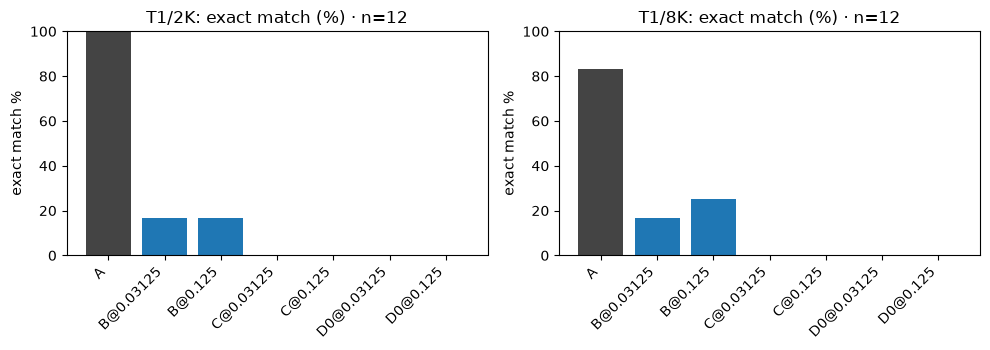

In [10]:
import matplotlib
import matplotlib.pyplot as plt
if summary and summary["comparison_methods"]:
    cells_ = list(summary["comparison_methods"].keys())
    fig, axes = plt.subplots(1, len(cells_), figsize=(5 * len(cells_), 3.6), squeeze=False)
    for ax, c in zip(axes[0], cells_):
        tbl = summary["comparison_methods"][c]; names = list(tbl.keys()); vals = [tbl[k]["rate"] * 100 for k in names]
        ax.bar(range(len(names)), vals, color=["#444" if k == "A" else ("#1f77b4" if k.startswith("B") else "#ff7f0e" if k.startswith("C") else "#2ca02c") for k in names])
        ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right"); ax.set_ylim(0, 100); ax.set_title(f"{c}: exact match (%) · n={tbl['A']['n']}"); ax.set_ylabel("exact match %")
    plt.tight_layout(); plt.show()


In [11]:
# 覆盖率：每步每层每组读到的被查询记录 token 占比；与 k/M 的期望并排
if summary and summary["comparison_methods"]:
    import statistics
    comp_rows = [r for r in answers if r["run_id"] == summary["comparison_run"] and r["variant"] == "base" and r["method"] != "A"]
    print(f"{'长度':<4} {'方法':<10} {'k/M 期望':>9} {'问题阶段':>9} {'生成阶段':>9} {'首生成步 均值/最低层/最高层':>28}")
    for lt in sorted({r["length_tag"] for r in comp_rows}):
        for mk in sorted({f"{r['method']}@{r['rho']:g}" for r in comp_rows}):
            rs = [r for r in comp_rows if r["length_tag"] == lt and f"{r['method']}@{r['rho']:g}" == mk]
            if not rs: continue
            k0 = rs[0]["k0"]; M = rs[0]["legal_start"] - 68
            fl = [r["coverage_first_gen_step_per_layer"] for r in rs]
            per_layer = [statistics.mean(x[l] for x in fl) for l in range(len(fl[0]))]
            print(f"{lt:<4} {mk:<10} {k0/M*100:>8.1f}% {statistics.mean(r['coverage_question_steps'] for r in rs)*100:>8.1f}% {statistics.mean(r['coverage_generation_steps'] for r in rs if r['coverage_generation_steps'] is not None)*100:>8.1f}% {statistics.mean(r['coverage_first_gen_step_mean'] for r in rs)*100:>9.1f}% / {min(per_layer)*100:.1f}% / {max(per_layer)*100:.1f}%")


长度   方法            k/M 期望      问题阶段      生成阶段              首生成步 均值/最低层/最高层
2K   B@0.03125       3.2%     16.7%     16.7%      16.7% / 16.7% / 16.7%
2K   B@0.125        12.9%     33.3%     33.3%      33.3% / 33.3% / 33.3%
2K   C@0.03125       3.2%      5.2%      3.2%       3.2% / 2.3% / 4.7%
2K   C@0.125        12.9%     14.7%     12.7%      12.8% / 10.8% / 14.5%
2K   D0@0.03125      3.2%      6.5%      4.9%       4.5% / 0.8% / 8.8%
2K   D0@0.125       12.9%     17.4%     16.6%      15.4% / 5.9% / 26.2%
8K   B@0.03125       3.1%     33.3%     33.3%      33.3% / 33.3% / 33.3%
8K   B@0.125        12.6%     33.3%     33.3%      33.3% / 33.3% / 33.3%
8K   C@0.03125       3.1%      8.8%      3.1%       3.2% / 2.6% / 4.5%
8K   C@0.125        12.6%     17.7%     12.6%      12.6% / 11.4% / 14.9%
8K   D0@0.03125      3.1%     12.0%      7.5%       6.7% / 1.5% / 14.8%
8K   D0@0.125       12.6%     22.4%     19.3%      17.0% / 4.6% / 34.6%


**观察。** 在 3% 到 13% 的读取比例下：C 与 D0 的完整匹配 0/12 ×4；B 2/12（2K 两档）、2/12 与 3/12（8K）；A 12/12 与 10/12。没有任何一个请求出现「A 错而稀疏读取对」。错误形态几乎只有一种：**答成问题里的编号**——C 48 个请求 47 个、D0 48/48、B 窗口外 34 个请求 33 个。B 在窗口外 0/34；窗口内 9/14，五个窗口内答错的请求全部发生在 2K 的大名额（ρ = 1/8）或 8K，且同一份资料上 1/32 对、1/8 错出现两次。覆盖率表证实了结构：C 的覆盖率与 k / M 相差不到 0.1 个百分点；D0 高于 k / M（1.2 到 2.2 倍，中间层更成簇），但没有一个层组完整读到那条记录（最高 2%）。A 重跑 24/24 逐位相同。

**解释。** 少读历史时丢掉的不是「答错的记录」，而是「检索本身」：模型退回到复述它能看到的唯一四位数（F 的近 64 永远包含问题）。这是关联：无法由此判断是「没找到就复述最近的数字」这一退化策略，还是「不要输出编号」这个否定指令在小模型上失效。对 B，记录在窗口内是必要条件不是充分条件——候选解释（表头不在 F 里、窗口从句中切入、问题 token 的 K/V 在部分读取下算出、窗口越大干扰越多）都没有分离。

**不能推出什么。** D0 的零不是索引方法的上限（它没训练过）；B 的数字依赖「F ∪ 最近 k 个候选」这个定义；中间档 ρ 没有数据；每步耗时含记账与同步，不是速度基准。

## 5. 代表案例

预登记的选法：每个可用格子、每一类（A 对 B 错；A 对 C 或 D0 错；四种都对）按资料序号取最多两份；存在才展示。每个案例按固定结构：资料与问题 → 运行前预测 → 四种方法实际回答 → 各自选择的位置 → 改动一处资料再检查 → 哪些解释得到支持、哪些仍不确定。下面的代码按类别打印案例；解释写在其后的文字格里。

In [12]:
def show_case(doc_id):
    d = summary["case_details"][doc_id]; doc = d["doc"]
    print("=" * 110)
    print(f"资料 {doc_id} · {doc['task']} {doc['length_tag']} · 目标桶 {doc['buckets']} · 倒数第 {doc['target_records_from_end']} 条 · 距前缀末尾 {doc['target_distance_from_prefix_end']} token · 前缀 {doc['prefix_token_count']} token")
    print("问题:", doc["question"]); print("目标值:", doc["targets"], "| 目标附近的记录 (编号, 值):", d["records_around_targets"], "| 资料末尾的记录:", d["last_records"])
    print(f"{'方法':<10} {'读取':>5} {'回答':<34} {'判定':<8} {'目标覆盖 首生成步 均值':>22} {'层组全覆盖比例':>14}")
    for mk, an in d["answers"].items():
        cov = an["coverage"]
        print(f"{mk:<10} {str(an['selected_count'] or '全部'):>5} {an['text'][:32]!r:<34} {'✓' if an['exact'] else '✗'}{'(答成编号)' if an.get('answered_with_ids') else '':<8} {('全部' if mk == 'A' else f'{cov.get('first_gen_step_mean', 0)*100:.1f}%'):>22} {('—' if mk == 'A' else f'{cov.get('fraction_of_layer_groups_with_full_coverage_first_gen_step', 0)*100:.0f}%'):>14}")
    for mk, an in d["answers"].items():
        pos = an.get("positions")
        if not pos: continue
        ex = pos["example_rows"]
        print(f"  {mk} 第一个生成 token 那一步的名单（第 0 组）：" + "; ".join(f"{k}: {v['n_rows']} 行, {v['n_ranges']} 段, 前几段 {v['ranges'][:6]}" for k, v in ex.items()))
    if d["rewrites"]:
        print("  改写：" + " | ".join(f"{r['variant']}→{r['method']}{'@'+format(r['rho'],'g') if r['rho'] is not None else ''} 答 {r['predicted']} 目标 {r['targets']} {'✓' if r['exact'] else '✗'}" for r in d["rewrites"]))

def plot_case_coverage(doc_id):
    d = summary["case_details"][doc_id]
    fig, ax = plt.subplots(figsize=(8, 3))
    for mk, an in d["answers"].items():
        if mk == "A" or not an["coverage"].get("first_gen_step_per_layer"): continue
        ax.plot(an["coverage"]["first_gen_step_per_layer"], marker="o", ms=3, label=mk)
    ax.set_xlabel("layer"); ax.set_ylabel("fraction of target positions read"); ax.set_ylim(-0.02, 1.02); ax.set_title(f"{doc_id}: target coverage per layer at the first generated token"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

if summary:
    cats = {}
    for c in summary["cases"]:
        cats.setdefault(c["category"], []).append(c)
    print({k: [x["doc_id"] for x in v] for k, v in cats.items()})


{'A_right_B_wrong': ['T1-2K-00', 'T1-2K-01', 'T1-8K-00', 'T1-8K-01'], 'A_right_C_or_D0_wrong': ['T1-2K-00', 'T1-2K-01', 'T1-8K-00', 'T1-8K-01'], 'B_right_C_and_D0_wrong': ['T1-2K-08', 'T1-2K-09', 'T1-8K-08', 'T1-8K-09'], 'B_wrong_target_in_window': ['T1-2K-08', 'T1-2K-10', 'T1-8K-09', 'T1-8K-11']}


### 5.1 A 对 B 错

**运行前的预测。** 大量存在（front / middle 目标）；关键记录在窗口外；把记录移近后 B 变对的比例 ≥ 3/4。

资料 T1-2K-00 · T1 2K · 目标桶 ['front'] · 倒数第 [15] 条 · 距前缀末尾 [1888] token · 前缀 2050 token
问题: 问题：编号 1563 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标值: ['8422'] | 目标附近的记录 (编号, 值): {'0': ['7303', '8080']} | 资料末尾的记录: [['8625', '6309'], ['7457', '7558'], ['4601', '6179'], ['4186', '3363'], ['1567', '8340'], ['2121', '8859']]
方法            读取 回答                                 判定                 目标覆盖 首生成步 均值        层组全覆盖比例
A             全部 '8422'                             ✓                             全部              —
B@0.03125    132 '1563'                             ✗(答成编号)                     0.0%             0%
B@0.125      324 '8340'                             ✗                           0.0%             0%
C@0.03125    132 '1563'                             ✗(答成编号)                     3.8%             0%
C@0.125      324 '1563'                             ✗(答成编号)                    13.0%             0%
D0@0.03125   132 '1563'                             ✗(答成编号)                     5.0%        

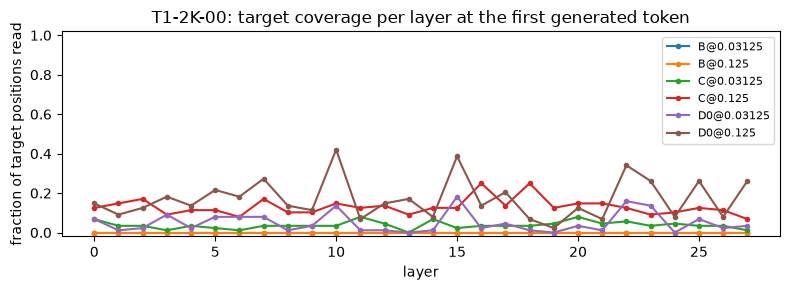

资料 T1-2K-01 · T1 2K · 目标桶 ['front'] · 倒数第 [14] 条 · 距前缀末尾 [1787] token · 前缀 2060 token
问题: 问题：编号 1066 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标值: ['7745'] | 目标附近的记录 (编号, 值): {'1': ['3449', '2603']} | 资料末尾的记录: [['1799', '2875'], ['8917', '9534'], ['7060', '7815'], ['5115', '4342'], ['2569', '1669'], ['5735', '5592']]
方法            读取 回答                                 判定                 目标覆盖 首生成步 均值        层组全覆盖比例
A             全部 '7745'                             ✓                             全部              —
B@0.03125    132 '1066'                             ✗(答成编号)                     0.0%             0%
B@0.125      326 '1066'                             ✗(答成编号)                     0.0%             0%
C@0.03125    132 '1066'                             ✗(答成编号)                     3.3%             0%
C@0.125      326 '1066'                             ✗(答成编号)                    13.1%             0%
D0@0.03125   132 '1066'                             ✗(答成编号)                     3.7%        

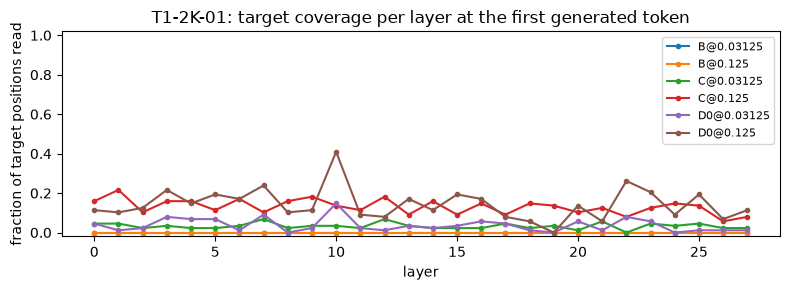

资料 T1-8K-00 · T1 8K · 目标桶 ['front'] · 倒数第 [15] 条 · 距前缀末尾 [7626] token · 前缀 8202 token
问题: 问题：编号 1553 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标值: ['6429'] | 目标附近的记录 (编号, 值): {'0': ['4738', '7258']} | 资料末尾的记录: [['5785', '7976'], ['2188', '5403'], ['7121', '2679'], ['5686', '2721'], ['7993', '1881'], ['8681', '3937']]
方法            读取 回答                                 判定                 目标覆盖 首生成步 均值        层组全覆盖比例
A             全部 '6429'                             ✓                             全部              —
B@0.03125    324 '1553'                             ✗(答成编号)                     0.0%             0%
B@0.125     1093 '1553'                             ✗(答成编号)                     0.0%             0%
C@0.03125    324 '1553'                             ✗(答成编号)                     3.1%             0%
C@0.125     1093 '1553'                             ✗(答成编号)                    12.9%             0%
D0@0.03125   324 '1553'                             ✗(答成编号)                     8.6%        

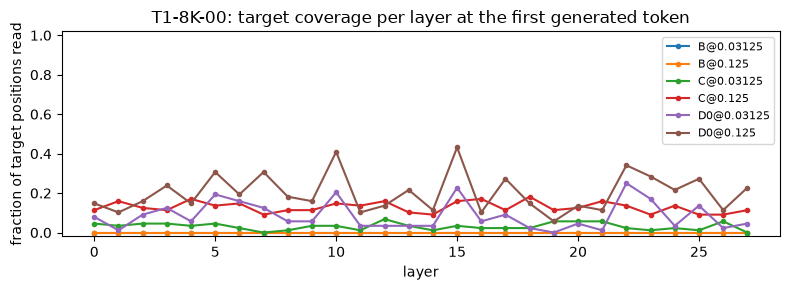

资料 T1-8K-01 · T1 8K · 目标桶 ['front'] · 倒数第 [14] 条 · 距前缀末尾 [7073] token · 前缀 8190 token
问题: 问题：编号 3090 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标值: ['5498'] | 目标附近的记录 (编号, 值): {'1': ['9862', '6912']} | 资料末尾的记录: [['3391', '4247'], ['2368', '8270'], ['9435', '5221'], ['9684', '7500'], ['3220', '4895'], ['5213', '8988']]
方法            读取 回答                                 判定                 目标覆盖 首生成步 均值        层组全覆盖比例
A             全部 '5498'                             ✓                             全部              —
B@0.03125    324 '3090'                             ✗(答成编号)                     0.0%             0%
B@0.125     1092 '3090'                             ✗(答成编号)                     0.0%             0%
C@0.03125    324 '3090'                             ✗(答成编号)                     2.6%             0%
C@0.125     1092 '3090'                             ✗(答成编号)                    12.2%             0%
D0@0.03125   324 '3090'                             ✗(答成编号)                     6.7%        

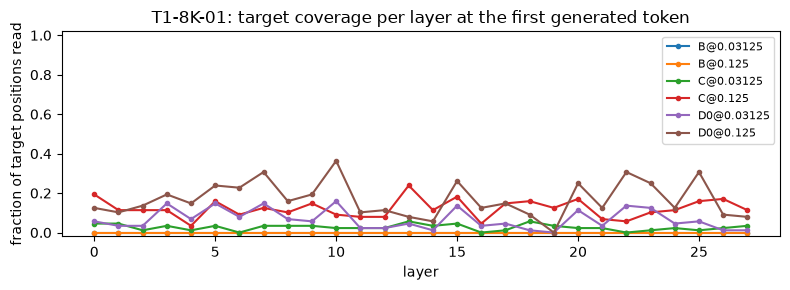

In [13]:
if summary:
    for c in [x for x in summary["cases"] if x["category"] == "A_right_B_wrong"]:
        show_case(c["doc_id"]); plot_case_coverage(c["doc_id"])
    if not [x for x in summary["cases"] if x["category"] == "A_right_B_wrong"]:
        print("本类案例不存在（存在才展示）")


**哪些解释得到支持。** 四份 front 目标距前缀末尾 1787 到 7626 token，B 的名单是首 4 ∪ 最后 132 / 324（2K）或 324 / 1092（8K）个位置，对目标的覆盖率为 0，于是 B 与 C、D0 一样答成编号；A 答对。移近改写（把被查询记录与倒数第一条互换）：T1-2K-00 两档变对，T1-8K-00 只在 1/32 变对，T1-8K-01 只在 1/8 变对，T1-2K-01 两档仍答编号——按资料 3/4 支持「关键记录在窗口外」这一解释，按（资料, ρ）只有 4/8。**仍不确定。** 为什么同一条记录移进窗口后，B 在一档对、另一档错；T1-2K-01 为什么两档都不对。value 改写里 A 跟着新值走（3/3），B / C / D0 的回答纹丝不动（24/24 仍是编号）：它们的输出与那条记录的内容无关，这是「没读到」的签名。

### 5.2 A 对 C 或 D0 错

**运行前的预测。** 几乎处处存在；被查询记录的 token 在绝大多数层组里没有被选中，覆盖率 ≈ k/M。

资料 T1-2K-00 · T1 2K · 目标桶 ['front'] · 倒数第 [15] 条 · 距前缀末尾 [1888] token · 前缀 2050 token
问题: 问题：编号 1563 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标值: ['8422'] | 目标附近的记录 (编号, 值): {'0': ['7303', '8080']} | 资料末尾的记录: [['8625', '6309'], ['7457', '7558'], ['4601', '6179'], ['4186', '3363'], ['1567', '8340'], ['2121', '8859']]
方法            读取 回答                                 判定                 目标覆盖 首生成步 均值        层组全覆盖比例
A             全部 '8422'                             ✓                             全部              —
B@0.03125    132 '1563'                             ✗(答成编号)                     0.0%             0%
B@0.125      324 '8340'                             ✗                           0.0%             0%
C@0.03125    132 '1563'                             ✗(答成编号)                     3.8%             0%
C@0.125      324 '1563'                             ✗(答成编号)                    13.0%             0%
D0@0.03125   132 '1563'                             ✗(答成编号)                     5.0%        

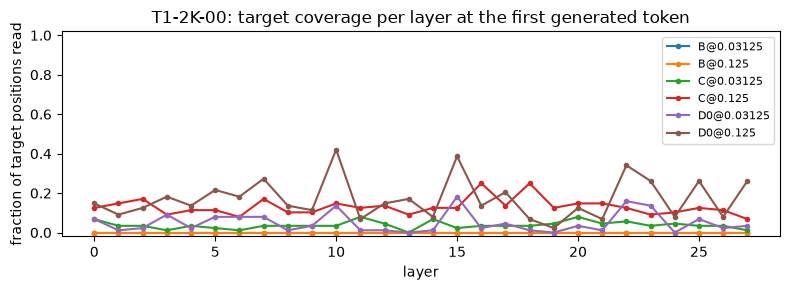

资料 T1-2K-01 · T1 2K · 目标桶 ['front'] · 倒数第 [14] 条 · 距前缀末尾 [1787] token · 前缀 2060 token
问题: 问题：编号 1066 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标值: ['7745'] | 目标附近的记录 (编号, 值): {'1': ['3449', '2603']} | 资料末尾的记录: [['1799', '2875'], ['8917', '9534'], ['7060', '7815'], ['5115', '4342'], ['2569', '1669'], ['5735', '5592']]
方法            读取 回答                                 判定                 目标覆盖 首生成步 均值        层组全覆盖比例
A             全部 '7745'                             ✓                             全部              —
B@0.03125    132 '1066'                             ✗(答成编号)                     0.0%             0%
B@0.125      326 '1066'                             ✗(答成编号)                     0.0%             0%
C@0.03125    132 '1066'                             ✗(答成编号)                     3.3%             0%
C@0.125      326 '1066'                             ✗(答成编号)                    13.1%             0%
D0@0.03125   132 '1066'                             ✗(答成编号)                     3.7%        

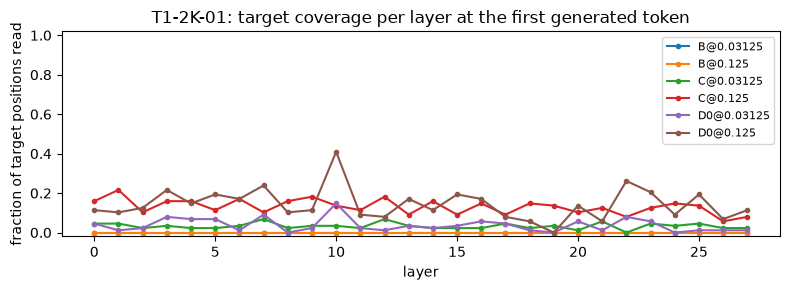

资料 T1-8K-00 · T1 8K · 目标桶 ['front'] · 倒数第 [15] 条 · 距前缀末尾 [7626] token · 前缀 8202 token
问题: 问题：编号 1553 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标值: ['6429'] | 目标附近的记录 (编号, 值): {'0': ['4738', '7258']} | 资料末尾的记录: [['5785', '7976'], ['2188', '5403'], ['7121', '2679'], ['5686', '2721'], ['7993', '1881'], ['8681', '3937']]
方法            读取 回答                                 判定                 目标覆盖 首生成步 均值        层组全覆盖比例
A             全部 '6429'                             ✓                             全部              —
B@0.03125    324 '1553'                             ✗(答成编号)                     0.0%             0%
B@0.125     1093 '1553'                             ✗(答成编号)                     0.0%             0%
C@0.03125    324 '1553'                             ✗(答成编号)                     3.1%             0%
C@0.125     1093 '1553'                             ✗(答成编号)                    12.9%             0%
D0@0.03125   324 '1553'                             ✗(答成编号)                     8.6%        

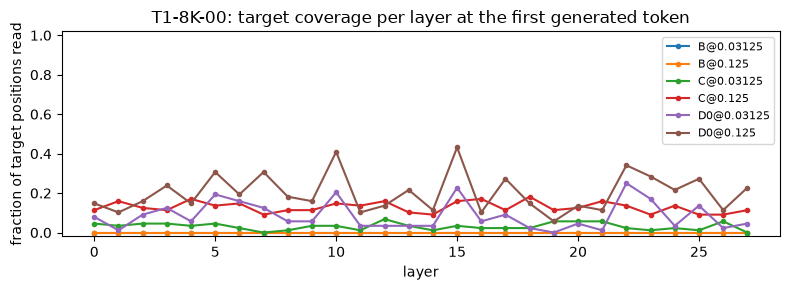

资料 T1-8K-01 · T1 8K · 目标桶 ['front'] · 倒数第 [14] 条 · 距前缀末尾 [7073] token · 前缀 8190 token
问题: 问题：编号 3090 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标值: ['5498'] | 目标附近的记录 (编号, 值): {'1': ['9862', '6912']} | 资料末尾的记录: [['3391', '4247'], ['2368', '8270'], ['9435', '5221'], ['9684', '7500'], ['3220', '4895'], ['5213', '8988']]
方法            读取 回答                                 判定                 目标覆盖 首生成步 均值        层组全覆盖比例
A             全部 '5498'                             ✓                             全部              —
B@0.03125    324 '3090'                             ✗(答成编号)                     0.0%             0%
B@0.125     1092 '3090'                             ✗(答成编号)                     0.0%             0%
C@0.03125    324 '3090'                             ✗(答成编号)                     2.6%             0%
C@0.125     1092 '3090'                             ✗(答成编号)                    12.2%             0%
D0@0.03125   324 '3090'                             ✗(答成编号)                     6.7%        

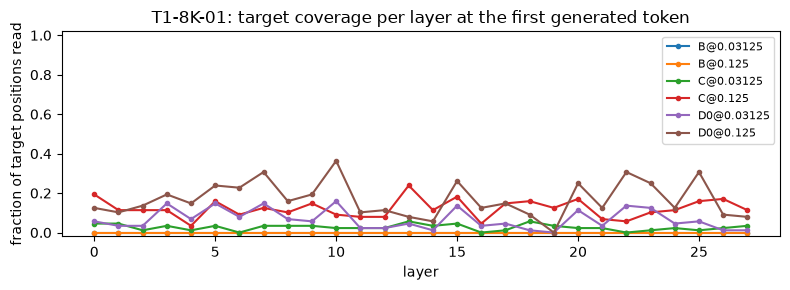

In [14]:
if summary:
    for c in [x for x in summary["cases"] if x["category"] == "A_right_C_or_D0_wrong"]:
        show_case(c["doc_id"]); plot_case_coverage(c["doc_id"])
    if not [x for x in summary["cases"] if x["category"] == "A_right_C_or_D0_wrong"]:
        print("本类案例不存在（存在才展示）")


**哪些解释得到支持。** 与上一类是同四份资料（预登记规则按序号取，恰好重合）。C 的名单在三层的例子里各是约 60 到 250 段单个位置，对目标 11 个 token 的覆盖率 3%–13%；D0 的名单段数更少（第 14 层 162 段对 C 的 224 段）、覆盖率 5%–20%，但层组完整覆盖的比例 0%–2%。两者都答编号。这支持「覆盖率 ≈ k/M 时无法抄出四位值」的结构解释，也支持「D0 偏好目标 token 但远远不够」。**仍不确定。** D0 偏好目标 token 的机制（问题里的数字 token 投影后与资料里的数字 token 更接近）是假设，没有单独验证。

### 5.3 四种方法都对

**运行前的预测。** 不存在或 ≤ 2 份；若出现，C / D0 在若干层里恰好选中了值的数字 token，而不是靠 F。

In [15]:
if summary:
    for c in [x for x in summary["cases"] if x["category"] == "all_four_right"]:
        show_case(c["doc_id"]); plot_case_coverage(c["doc_id"])
    if not [x for x in summary["cases"] if x["category"] == "all_four_right"]:
        print("本类案例不存在（存在才展示）")


本类案例不存在（存在才展示）


**本类不存在**：C 与 D0 没有答对任何一份资料，所以没有「四种方法都对」的样本。卡片预测的是「不存在或 ≤ 2 份」，成立。

## 6. 反事实改写：只改一处资料再检查

**运行前的预测。** A：改被查询记录的值后答案跟着改（≥ 90%），改无关记录后不变（≥ 90%）。B：目标在窗口外时改值后回答不变（它没读到），这是窗口基线的签名。C：改无关记录时回答不变 ≥ 70%；D0 ≥ 50%。移位改写：A 仍对的样本上 B 变对 ≥ 3/4。

In [16]:
if summary and summary["rewrites"]:
    from collections import defaultdict
    agg = defaultdict(lambda: [0, 0])
    for r in summary["rewrites"]:
        key = {"value": "answer_followed_change", "irrelevant": "answer_unchanged", "move": "became_right"}[r["variant"]]
        mk = r["method"] if r["rho"] is None else f"{r['method']}@{r['rho']:g}"
        agg[(r["variant"], mk)][0] += int(bool(r.get(key))); agg[(r["variant"], mk)][1] += 1
    print(f"{'改写':<11} {'方法':<10} {'检查':<22} {'成立/样本':>10}")
    for (v, mk), (x, n) in sorted(agg.items()):
        print(f"{v:<11} {mk:<10} {({'value': '答案跟着改', 'irrelevant': '答案不变', 'move': '移近后变对'}[v]):<22} {x:>4}/{n:<4}")
    print()
    for r in summary["rewrites"]:
        mk = r["method"] if r["rho"] is None else f"{r['method']}@{r['rho']:g}"
        print(f"  {r['variant']:<10} {r['parent_doc_id']:<10} {mk:<10} 原答 {r['base_predicted']} ({'✓' if r['base_exact'] else '✗'}) → 改后答 {r['rewrite_predicted']} 目标 {r['rewrite_targets']} ({'✓' if r['rewrite_exact'] else '✗'})  {r.get('note')}")


改写          方法         检查                          成立/样本
irrelevant  A          答案不变                      4/4   
irrelevant  B@0.03125  答案不变                      4/4   
irrelevant  B@0.125    答案不变                      3/4   
irrelevant  C@0.03125  答案不变                      4/4   
irrelevant  C@0.125    答案不变                      4/4   
irrelevant  D0@0.03125 答案不变                      4/4   
irrelevant  D0@0.125   答案不变                      4/4   
move        A          移近后变对                     0/4   
move        B@0.03125  移近后变对                     2/4   
move        B@0.125    移近后变对                     2/4   
move        C@0.03125  移近后变对                     0/4   
move        C@0.125    移近后变对                     0/4   
move        D0@0.03125 移近后变对                     0/4   
move        D0@0.125   移近后变对                     0/4   
value       A          答案跟着改                     3/4   
value       B@0.03125  答案跟着改                     0/4   
value       B@0.125    答案跟着改                   

**观察。** value：A 原本答对的 3 份全部跟着改成新值（T1-8K-04 原本答错，改后仍答同一条错误记录的值）；B / C / D0 的 24 个请求全部仍答编号——它们的输出与被查询记录的内容无关。irrelevant：A 4/4 不变；B 7/8、C 8/8、D0 8/8 不变（唯一变化是 T1-2K-00 的 B ρ = 1/8 从窗口内另一条记录的值 8340 变成编号 1563，同样错）。move：A 4/4 仍对；B 按资料 3/4、按（资料, ρ）4/8 变对；C / D0 16 个请求 15 个仍答编号。

**解释。** 三种改写把「答对」和「读到」绑在一起：A 的答案随被查询的值变、不随无关值变，说明 A 的检索是对那条记录的；B 只有在记录进入窗口后答案才可能改变；C / D0 的答案对资料内容不敏感。**不能推出什么。** C / D0 在 irrelevant 上的「不变」没有信息量——它们本来就只会回声编号。

## 7. 实际运行成本

In [17]:
if summary:
    print("设备时间 s:", {k: (round(v) if isinstance(v, (int, float)) else v) for k, v in summary["device_seconds"].items()})
    for name, tm in (("baseline", summary["timing"]["baseline"]), ("comparison", summary["timing"]["comparison"]), *[(f"rewrites[{i}]", t) for i, t in enumerate(summary["timing"]["rewrites"])]):
        if tm:
            print(name, "| prefill ms 中位:", tm["prefill_ms_median_by_length"], "| 每步 ms 中位:", {k: round(v, 1) for k, v in tm["ms_per_step_median"].items()})


设备时间 s: {'baseline': 86, 'comparison': 151, 'rewrites': [50.41356487502344, 25.87450237502344], 'total': 313}
baseline | prefill ms 中位: {'2K': 316.8925204954576, '8K': 1837.1775624982547} | 每步 ms 中位: {'2K/A': 11.2, '8K/A': 13.0}
comparison | prefill ms 中位: {'2K': 315.91568753356114, '8K': 1755.2548329986166} | 每步 ms 中位: {'2K/A': 11.1, '2K/B@0.03125': 11.7, '2K/B@0.125': 11.8, '2K/C@0.03125': 20.5, '2K/C@0.125': 21.8, '2K/D0@0.03125': 18.1, '2K/D0@0.125': 17.6, '8K/A': 12.8, '8K/B@0.03125': 11.9, '8K/B@0.125': 12.2, '8K/C@0.03125': 30.7, '8K/C@0.125': 35.6, '8K/D0@0.03125': 17.9, '8K/D0@0.125': 17.8}
rewrites[0] | prefill ms 中位: {'2K': 356.0389585036319, '8K': 1781.0878335149027} | 每步 ms 中位: {'2K/A': 10.8, '2K/B@0.03125': 11.5, '2K/B@0.125': 11.5, '2K/C@0.03125': 20.5, '2K/C@0.125': 22.2, '2K/D0@0.03125': 17.6, '2K/D0@0.125': 17.6, '8K/A': 12.5, '8K/B@0.03125': 11.6, '8K/B@0.125': 12.0, '8K/C@0.03125': 29.8, '8K/C@0.125': 34.3, '8K/D0@0.03125': 17.4, '8K/D0@0.125': 17.7}
rewrites[1] | p

**读法。** 正式三遍 313 s，加冒烟与校准 654 s，现金 0，分配内存峰值 3.4 GB。每步耗时：A 11–13 ms，B 与 A 相当，D0 约 18 ms（G1b 测过的小核链），C 20–36 ms——C 的额外成本是 CPU 上 numpy 的均匀抽样与 top-k（每层每步一次，8K 候选域更大），不是 GPU 属性，也不是本任务的测量对象。

## 8. 预测对照与结论

| 项 | 预测 | 实测 | 判定 |
|---|---|---|---|
| 基线：T1 两档可用，T2 两档不可用 | 2K 10–12 / 8K 9–12；T2 3–7 / 0–3 | 12 / 10；8 / 1 | 成立（T2-2K 略高于区间，仍 < 80%） |
| B 窗口外全错 | 是 | 0/34 | 成立 |
| B 窗口内全对（T1 2/12、4/12；4/12、4/12） | 是 | 2、2；2、3（窗口内 9/14） | **失效**：窗口内命中率 64%，名额变大反而变错 |
| B 错时答窗口内近期记录的值或编造数 | 是 | 33/34 答编号 | 部分成立 |
| 移近后 B 变对 ≥ 3/4 | 是 | 按资料 3/4；按设置 4/8 | 资料口径成立 |
| C 接近零；覆盖率 = k/M | 是 | 0/12 ×4；偏差 ≤ 0.1 pp | 成立 |
| C 错误以编造数为主 | 是 | 47/48 编号回声 | 失效 |
| D0 不优于 C；覆盖率 ≈ k/M | 六成 | 0/12 ×4；覆盖率 1.2–2.2 × k/M | 成绩成立；覆盖率均值失效 |
| 四种都对不存在或 ≤ 2 | 是 | 不存在 | 成立 |
| 反事实签名 | A 跟着改 / 不变；B 窗口外改值不变 | 3/3、4/4；24/24 | 成立 |
| 成本 ≤ 40 min，峰值 < 8 GB | 是 | 11 min；3.4 GB | 成立；C / D0 每步成本高于预测 |

**结论（限 Qwen3-0.6B、bf16、MPS、本任务格式、48 份探索样本）。** 当模型只能读 3% 到 13% 的历史时，丢掉的不是「答错的记录」而是「检索本身」：未训练索引 D0 与均匀随机 C 一样为零，窗口 B 只在被查询记录落入窗口时可能答对（窗口内 9/14、窗口外 0/34），所有失败几乎都退化为复述问题里的编号。D0 的名单确实偏向目标记录的 token（1.2 到 2.2 倍于均匀），但远不足以抄出值——这给 G3 留下了一个清楚的量化目标（层组完整覆盖比例从 0–2% 升到多少才够），而不是一个承诺。T2 在本模型上基线不可用，没有稀疏读取结论。`03_G2_TO_G5.md` 保持 BLOCKED；下一步（单变量重放 B 的窗口内失败、更大模型复测 T2、训练索引器）都需要用户另行授权。